# Figure 4: Reset Therapy in the VEGF Model

In [ ]:
"""Imports and plotting utilities for Figure 4 (VEGF model)."""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.transforms import ScaledTranslation
from scipy.integrate import odeint
import sys
sys.path.insert(0, '../src')
from rpa_control.style import set_style
from rpa_control.paths import save_fig
import seaborn as sns

set_style()
plt.rcParams['text.usetex'] = False

# ======================================================================
# Plotting helpers
# ======================================================================

def clean_ax(ax):
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

def text_panel(ax, lines, fontsize=11):
    ax.axis('off')
    ax.text(0.05, 0.95, '\n'.join(lines), transform=ax.transAxes,
            fontsize=fontsize, verticalalignment='top', family='serif', linespacing=1.8)


In [9]:
# ======================================================================
# VEGF model parameters, ODE, and integration helper
# ======================================================================
from scipy.integrate import solve_ivp as _solve_ivp

k1   = 5.0    # A1 (VEGF) production rate
k2   = 2.0    # A2 (compensatory) production rate
a1_v = 0.5    # VEGF effect on E growth
a2_v = 0.1    # compensatory signal effect on E growth
r_E  = 0.5    # endothelial cell death rate
mu_v = 0.25   # vascular scaling (E_ss = mu_v * C at steady state)
c1_v = 0.1    # tumor growth rate
c2_v = 1.0    # tumor removal rate
alpha1 = 0.01  # clearance rate of A1 (VEGF)
alpha2 = 0.01  # clearance rate of A2 (compensatory)
treatment_efficacy = 0.1  # fraction of a1_v remaining during treatment (0 = fully blocked, 1 = no effect)

C0_v = 16.0
E0_v = mu_v * C0_v   # = 4.0
A1_0 = 1.2963
A2_0 = 0.1852
y0_v = [A1_0, A2_0, E0_v, C0_v]

def vegf_rhs(t, y, a1_val):
    A1, A2, E, C = y
    deficit = mu_v * C - E
    dA1 = k1 * deficit - alpha1 * A1
    dA2 = k2 * deficit - alpha2 * A2
    dE  = E * ((a1_val * A1 + a2_v * A2) * (1 - E / (4 * mu_v * C0_v)) - r_E)
    dC  = C * (c1_v - c2_v * max(deficit, 0.0))
    return [dA1, dA2, dE, dC]

def _integrate_v(y0, T, a1_val, rtol=1e-4, atol=1e-7):
    sol = _solve_ivp(lambda t, y: vegf_rhs(t, y, a1_val),
                     (0, T), y0, method='RK45', rtol=rtol, atol=atol)
    result = list(sol.y[:, -1])
    return result if all(np.isfinite(v) for v in result) else None

print(f"VEGF IC: A1={A1_0:.4f}, A2={A2_0:.4f}, E={E0_v:.2f}, C={C0_v:.2f}")
print(f"Deficit at t=0: {mu_v*C0_v - E0_v:.4f}  (should be ~0)")
print(f"Treatment: a1_v * treatment_efficacy = {a1_v * treatment_efficacy:.4f}  (vs full {a1_v})")


VEGF IC: A1=1.2963, A2=0.1852, E=4.00, C=16.00
Deficit at t=0: 0.0000  (should be ~0)
Treatment: a1_v * treatment_efficacy = 0.0500  (vs full 0.5)


**Panel E** — VEGF model: equations and biological roles.

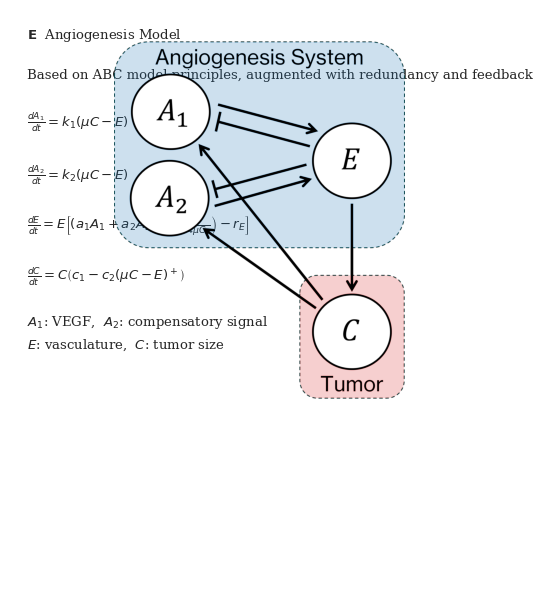

In [10]:
# Panel E: standalone — VEGF model ODEs + image
import os

fig_E, ax_E = plt.subplots(figsize=(5, 6))
ax_E.axis('off')

lines_E = [
    r'$\mathbf{E}$  Angiogenesis Model',
    '',
    r'Based on ABC model principles, augmented with redundancy and feedback',
    '',
    r'$\frac{dA_1}{dt} = k_1(\mu C - E)$',
    '',
    r'$\frac{dA_2}{dt} = k_2(\mu C - E)$',
    '',
    r'$\frac{dE}{dt} = E\left[(a_1 A_1 + a_2 A_2)\left(1-\frac{E}{4\mu C_0}\right) - r_E\right]$',
    '',
    r'$\frac{dC}{dt} = C\left(c_1 - c_2(\mu C - E)^+\right)$',
    '',
    r'$A_1$: VEGF,  $A_2$: compensatory signal',
    r'$E$: vasculature,  $C$: tumor size',
]
ax_E.text(0.05, 0.97, '\n'.join(lines_E), transform=ax_E.transAxes,
          fontsize=9.5, va='top', family='serif', linespacing=1.6)

VEGF_IMG = 'vegf_model.png'
if os.path.exists(VEGF_IMG):
    # move to the right a bit
    ax_eimg = ax_E.inset_axes([0.25, 0.3, 1.0, 0.65])
    ax_eimg.imshow(plt.imread(VEGF_IMG))
    ax_eimg.axis('off')

plt.tight_layout()
plt.show()


**Panel F** — VEGF model: growth vs. decay for fixed $T_{off}$, with three regimes.

/tmp/ipykernel_488649/3360370505.py:20: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  decay_v_arr[_i] = c2_v * np.trapz(_deficit, _t_full)


T_off_v = 5.0
Crossings: ['0.81', '30.54']
Optimal Ton (max net decay): 5.97


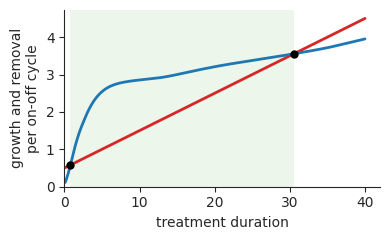


Using Ton_opt_v = 5.97 for Panel G
Figure saved to /home/amir/RL/autodiff-control/plots/figure4_V2_B.pdf


In [11]:
# ======================================================================
# Panel F: VEGF growth vs. decay with 3-regime annotations
# ======================================================================

T_OFF_V    = 5.0
Ton_scan_v = np.linspace(0.1, 40, 300)

growth_v_arr = c1_v * (Ton_scan_v + T_OFF_V)

# Direct integral: c2 * trapz( (mu*C - E)+, t ) over full cycle
decay_v_arr = np.empty_like(Ton_scan_v)
for _i, _ton in enumerate(Ton_scan_v):
    _t_on  = np.linspace(0, _ton, max(int(_ton * 50), 200))
    _s_on  = odeint(lambda y, t: vegf_rhs(t, y, a1_v * treatment_efficacy), list(y0_v), _t_on)
    _t_off = np.linspace(0, T_OFF_V, 300)
    _s_off = odeint(lambda y, t: vegf_rhs(t, y, a1_v), list(_s_on[-1]), _t_off)
    _t_full   = np.concatenate([_t_on, _ton + _t_off[1:]])
    _sol_full = np.concatenate([_s_on, _s_off[1:]])
    _deficit  = np.maximum(mu_v * _sol_full[:,3] - _sol_full[:,2], 0.0)
    decay_v_arr[_i] = c2_v * np.trapz(_deficit, _t_full)

_net_v    = decay_v_arr - growth_v_arr
_sign_chg = np.where(np.diff(np.sign(_net_v)))[0]
crossings_v = []
crossings_v_visual = []
for _idx in _sign_chg:
    _ta, _tb = Ton_scan_v[_idx], Ton_scan_v[_idx + 1]
    _frac = -_net_v[_idx] / (_net_v[_idx + 1] - _net_v[_idx])
    _cx = _ta + _frac * (_tb - _ta)
    crossings_v.append(_cx)
    _val = growth_v_arr[_idx] + _frac * (growth_v_arr[_idx + 1] - growth_v_arr[_idx])
    crossings_v_visual.append((_cx, _val))

Ton_opt_v = Ton_scan_v[np.nanargmax(_net_v)]
print(f'T_off_v = {T_OFF_V}')
print(f'Crossings: {[f"{c:.2f}" for c in crossings_v]}')
print(f'Optimal Ton (max net decay): {Ton_opt_v:.2f}')

# ── Plot ──────────────────────────────────────────────────────────────
fig_F, ax_F = plt.subplots(figsize=(4, 2.5))

# Green span for optimal window only (between crossings, where decay > growth)
if len(crossings_v) >= 2:
    ax_F.axvspan(crossings_v[0], crossings_v[1], color='#51A836', alpha=0.10, lw=0)
elif len(crossings_v) == 1 and _net_v[-1] > 0:
    ax_F.axvspan(crossings_v[0], Ton_scan_v[-1], color='#51A836', alpha=0.10, lw=0)

ax_F.plot(Ton_scan_v, growth_v_arr, color='C3', lw=2)
ax_F.plot(Ton_scan_v, decay_v_arr,  color='C0', lw=2)
ax_F.axhline(0, color='k', lw=0.5)

# Crossing dots
for _cx, _val in crossings_v_visual:
    ax_F.plot(_cx, _val, 'o', color='k', ms=6, zorder=6, mec='none')

# Optimal Ton line
_y_grow_opt_v = c1_v * (Ton_opt_v + T_OFF_V)
_y_dec_opt_v  = decay_v_arr[np.argmax(_net_v)]
_y_top_opt_v  = max(_y_grow_opt_v, _y_dec_opt_v)
_nudge_F = ScaledTranslation(0, 0.5/72, fig_F.dpi_scale_trans)
_trans_F = ax_F.transData + _nudge_F
# ax_F.plot([Ton_opt_v, Ton_opt_v], [0, _y_top_opt_v],
#           color='k', ls=':', lw=1.2, alpha=0.7)
# ax_F.plot(Ton_opt_v, _y_grow_opt_v, 'o', color='C3', ms=6, zorder=7, mec='none',
#           transform=_trans_F)
# ax_F.plot(Ton_opt_v, _y_dec_opt_v,  'o', color='C0', ms=6, zorder=7, mec='none',
#           transform=_trans_F)

ax_F.set_xlabel('treatment duration')
ax_F.set_ylabel('growth and removal\nper on-off cycle')
ax_F.set_ylim(bottom=0)
ax_F.set_xlim(left=0)
clean_ax(ax_F)
plt.tight_layout()
plt.show()

print(f'\nUsing Ton_opt_v = {Ton_opt_v:.2f} for Panel G')

save_fig(fig_F, 'figure4_B.pdf')


<>:86: SyntaxWarning: invalid escape sequence '\,'
<>:86: SyntaxWarning: invalid escape sequence '\,'
/tmp/ipykernel_1087435/1255838229.py:86: SyntaxWarning: invalid escape sequence '\,'
  axes_Fd[0, 0].set_ylabel('$A_1,\,A_2$',   fontsize=9)
/tmp/ipykernel_1087435/1255838229.py:96: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


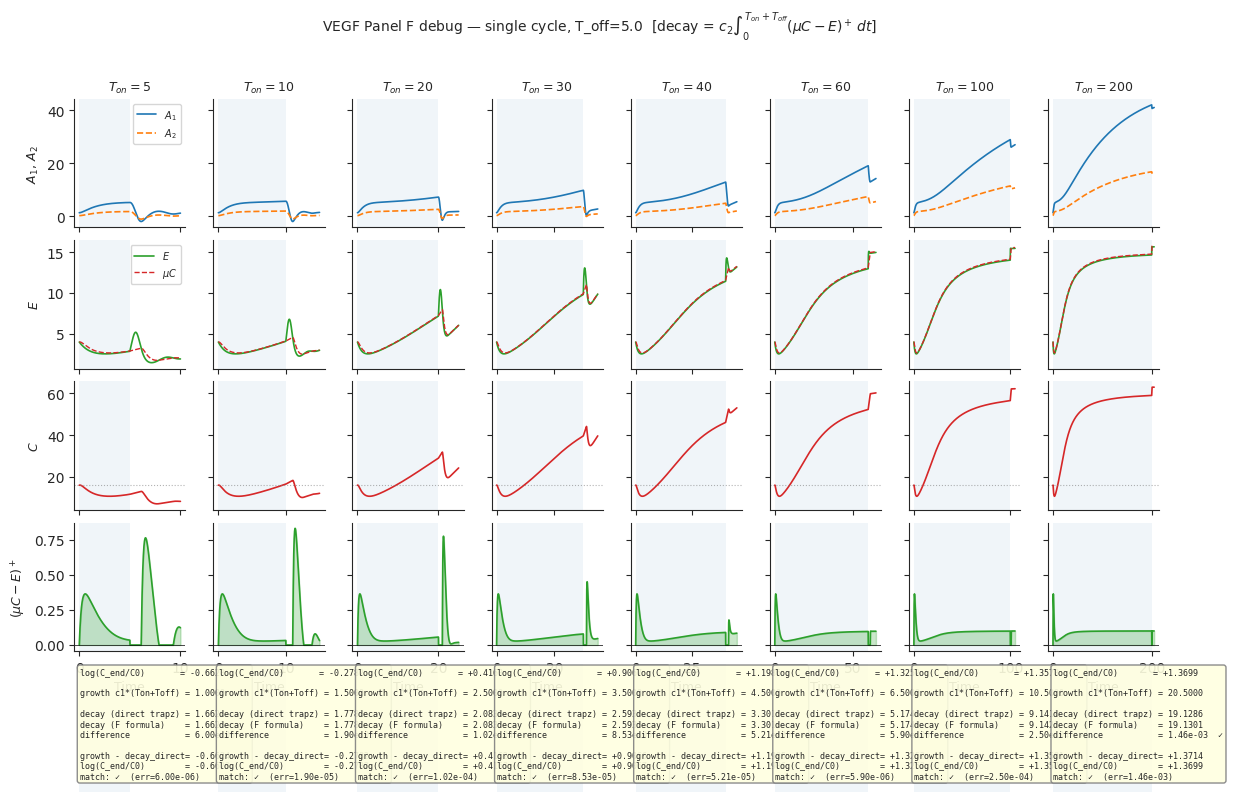

In [16]:
# ======================================================================
# Panel F debug: single-cycle simulation + direct integral verification
# ======================================================================
_Ton_debug = [5.0, 10.0, 20.0, 30.0, 40.0, 60.0, 100.0, 200.0]
_T_off_d   = T_OFF_V

fig_Fd, axes_Fd = plt.subplots(5, len(_Ton_debug), figsize=(14, 9),
                                sharex='col', sharey='row',
                                gridspec_kw={'hspace': 0.10, 'wspace': 0.25})

for col, _ton in enumerate(_Ton_debug):
    # ── Simulate one full cycle ───────────────────────────────────────
    _t_on   = np.linspace(0, _ton, 2000)
    _sol_on = odeint(lambda y, t: vegf_rhs(t, y, a1_v * treatment_efficacy), list(y0_v), _t_on)
    _t_off  = np.linspace(0, _T_off_d, 600)
    _sol_off = odeint(lambda y, t: vegf_rhs(t, y, a1_v), list(_sol_on[-1]), _t_off)

    _t   = np.concatenate([_t_on, _ton + _t_off[1:]])
    _sol = np.concatenate([_sol_on, _sol_off[1:]])
    _A1, _A2, _E, _C = _sol[:,0], _sol[:,1], _sol[:,2], _sol[:,3]

    # ── Direct computations ───────────────────────────────────────────
    # Deficit over FULL cycle (ON + OFF)
    _deficit_full = np.maximum(mu_v * _C - _E, 0.0)

    # 1. Actual log-fold change from simulation
    _logfold_actual = np.log(_C[-1] / y0_v[3])

    # 2. Direct growth: c1 * (Ton + Toff)
    _growth_direct = c1_v * (_ton + _T_off_d)

    # 3. Direct decay: c2 * integral over FULL cycle
    _decay_direct = c2_v * np.trapezoid(_deficit_full, _t)

    # 4. Formula-based decay (as in Panel F): growth - log(C_end/C0)
    _decay_formula = _growth_direct - _logfold_actual

    # 5. Check: growth - decay_direct should equal log-fold
    _check = _growth_direct - _decay_direct

    # ── Plot ─────────────────────────────────────────────────────────
    axs = axes_Fd[:, col]
    for _ax in axs:
        _ax.axvspan(0, _ton, color='steelblue', alpha=0.08, lw=0, zorder=0)
        clean_ax(_ax)

    axs[0].plot(_t, _A1, color='C0', lw=1.2, label='$A_1$')
    axs[0].plot(_t, _A2, color='C1', lw=1.2, ls='--', label='$A_2$')
    axs[1].plot(_t, _E,      color='C2', lw=1.2, label='$E$')
    axs[1].plot(_t, mu_v*_C, color='C3', lw=1.0, ls='--', label=r'$\mu C$')
    axs[2].plot(_t, _C, color='C3', lw=1.2)
    axs[2].axhline(y0_v[3], color='gray', ls=':', lw=0.8, alpha=0.6)

    # Row 3: deficit over full cycle, shaded
    axs[3].plot(_t, _deficit_full, color='C2', lw=1.2)
    axs[3].fill_between(_t, _deficit_full, alpha=0.25, color='C2')
    axs[3].axhline(0, color='k', lw=0.5)

    # Row 4: verification
    axs[4].axis('off')
    _err = abs(_decay_direct - _decay_formula)
    _lines = [
        f'log(C_end/C0)       = {_logfold_actual:+.4f}',
        '',
        f'growth c1*(Ton+Toff) = {_growth_direct:.4f}',
        '',
        f'decay (direct trapz) = {_decay_direct:.4f}',
        f'decay (F formula)    = {_decay_formula:.4f}',
        f'difference           = {_err:.2e}  {"✓" if _err < 1e-2 else "✗"}',
        '',
        f'growth - decay_direct= {_check:+.4f}',
        f'log(C_end/C0)        = {_logfold_actual:+.4f}',
        f'match: {"✓" if abs(_check-_logfold_actual)<1e-2 else "✗"}  (err={abs(_check-_logfold_actual):.2e})',
    ]
    axs[4].text(0.05, 0.97, '\n'.join(_lines), transform=axs[4].transAxes,
                ha='left', va='top', fontsize=6, family='monospace',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow',
                          edgecolor='gray', alpha=0.9))

    axs[0].set_title(rf'$T_{{on}}={_ton:.0f}$', fontsize=9)
    for _ax in axs[:4]:
        _ax.tick_params(labelbottom=False)
    axs[3].tick_params(labelbottom=True)
    axs[3].set_xlabel('Time', fontsize=9)

axes_Fd[0, 0].set_ylabel('$A_1,\,A_2$',   fontsize=9)
axes_Fd[1, 0].set_ylabel('$E$',            fontsize=9)
axes_Fd[2, 0].set_ylabel('$C$',            fontsize=9)
axes_Fd[3, 0].set_ylabel(r'$(\mu C-E)^+$', fontsize=9)
axes_Fd[0, 0].legend(fontsize=7, loc='upper right')
axes_Fd[1, 0].legend(fontsize=7, loc='upper right')

fig_Fd.suptitle(f'VEGF Panel F debug — single cycle, T_off={_T_off_d}  '
                r'[decay = $c_2\int_0^{T_{on}+T_{off}}(\mu C-E)^+\,dt$]',
                fontsize=10)
plt.tight_layout()
plt.show()


**Panel G** — VEGF adaptive therapy using the optimal $T_{on}$ from Panel F.

<>:52: SyntaxWarning: invalid escape sequence '\,'
<>:52: SyntaxWarning: invalid escape sequence '\,'
/tmp/ipykernel_488649/278769774.py:52: SyntaxWarning: invalid escape sequence '\,'
  axes_G[0].set_ylabel('$A_1,\,A_2$', fontsize=9)
/tmp/ipykernel_488649/278769774.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


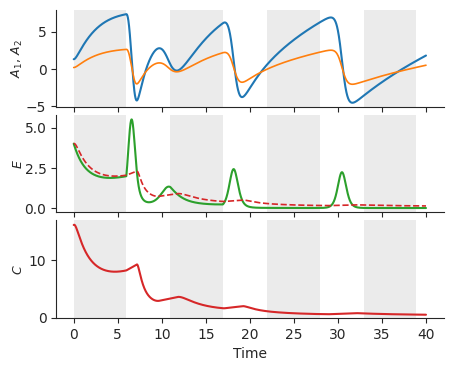

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_V2_C.pdf


In [12]:
# ======================================================================
# Panel G: VEGF adaptive therapy simulation
# ======================================================================
T_horizon_v = 40.0
Ton_G  = Ton_opt_v
Toff_G = T_OFF_V

t_all_v, _A1_all, _A2_all, _E_all, _C_all_v = [], [], [], [], []
on_spans_v = []
y_cur_v = list(y0_v)
t_cur   = 0.0

while t_cur < T_horizon_v:
    # ON phase (a1 reduced by treatment_efficacy)
    _t_on  = min(Ton_G, T_horizon_v - t_cur)
    _t_seg = np.linspace(0, _t_on, 400)
    _sol   = odeint(lambda y, t: vegf_rhs(t, y, a1_v * treatment_efficacy), y_cur_v, _t_seg)
    on_spans_v.append((t_cur, t_cur + _t_on))
    t_all_v.append(t_cur + _t_seg)
    _A1_all.append(_sol[:, 0]); _A2_all.append(_sol[:, 1])
    _E_all.append(_sol[:, 2]); _C_all_v.append(_sol[:, 3])
    t_cur += _t_on; y_cur_v = list(_sol[-1])
    if t_cur >= T_horizon_v: break
    # OFF phase
    _t_off = min(Toff_G, T_horizon_v - t_cur)
    _t_seg = np.linspace(0, _t_off, 400)
    _sol   = odeint(lambda y, t: vegf_rhs(t, y, a1_v), y_cur_v, _t_seg)
    t_all_v.append(t_cur + _t_seg)
    _A1_all.append(_sol[:, 0]); _A2_all.append(_sol[:, 1])
    _E_all.append(_sol[:, 2]); _C_all_v.append(_sol[:, 3])
    t_cur += _t_off; y_cur_v = list(_sol[-1])

t_vv  = np.concatenate(t_all_v)
A1_vv = np.concatenate(_A1_all)
A2_vv = np.concatenate(_A2_all)
E_vv  = np.concatenate(_E_all)
C_vv  = np.concatenate(_C_all_v)

fig_G, axes_G = plt.subplots(3, 1, figsize=(5, 4), sharex=True,
                              gridspec_kw={'hspace': 0.08})

for _ts, _te in on_spans_v:
    for ax in axes_G:
        ax.axvspan(_ts, _te, color='lightgray', alpha=0.45, lw=0, zorder=0)
        ax.yaxis.set_label_coords(-0.08, 0.5)

for ax in axes_G:
    clean_ax(ax)

axes_G[0].plot(t_vv, A1_vv, color='C0', lw=1.5, label='$A_1$  (VEGF)')
axes_G[0].plot(t_vv, A2_vv, color='C1', lw=1.2, label='$A_2$  (compensatory)')
axes_G[0].set_ylabel('$A_1,\,A_2$', fontsize=9)
# axes_G[0].legend(fontsize=7, loc='upper right')

axes_G[1].plot(t_vv, E_vv,           color='C2', lw=1.5, label='$E$')
axes_G[1].plot(t_vv, mu_v * C_vv,    color='C3', lw=1.2, ls='--', label=r'$\mu C$')
axes_G[1].set_ylabel('$E$', fontsize=9)
# axes_G[1].legend(fontsize=7, loc='upper right')

axes_G[2].plot(t_vv, C_vv, color='C3', lw=1.5)
axes_G[2].set_ylabel('$C$', fontsize=9)
# axes_G[2].yaxis.set_label_coords(-0.10, 0.5)
axes_G[2].set_xlabel('Time', fontsize=10)
axes_G[2].set_ylim(bottom=0)

# axes_G[0].set_title(
#     f'Adaptive therapy for the optimal treatment time found\n'
#     rf'($T_{{on}}={Ton_G:.1f}$, $T_{{off}}={Toff_G:.1f}$)',
#     fontsize=10)

plt.tight_layout()
plt.show()

save_fig(fig_G, 'figure4_C.pdf')


/tmp/ipykernel_488649/3079163404.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


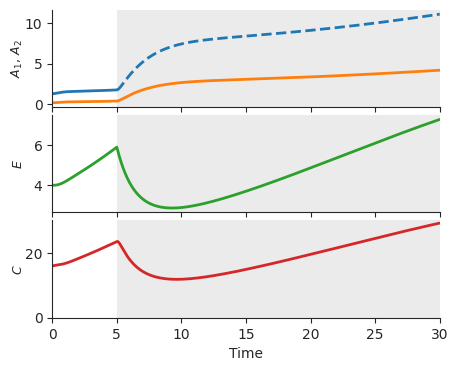

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_V2_A.pdf


In [13]:
# ======================================================================
# Panel H: VEGF continuous treatment simulation
# ======================================================================
LW = 2
T_pre_H   = 5.0   # no-treatment warm-up
T_treat_H = 25.0   # continuous treatment duration

# ── No-treatment phase ───────────────────────────────────────────────
_t_pre   = np.linspace(0, T_pre_H, 500)
_sol_pre = odeint(lambda y, t: vegf_rhs(t, y, a1_v), list(y0_v), _t_pre)

# ── Treatment phase ──────────────────────────────────────────────────
_t_tr   = np.linspace(0, T_treat_H, 3000)
_sol_tr = odeint(lambda y, t: vegf_rhs(t, y, a1_v * treatment_efficacy),
                 list(_sol_pre[-1]), _t_tr)

# ── Concatenate ──────────────────────────────────────────────────────
_t_H = np.concatenate([_t_pre, T_pre_H + _t_tr[1:]])
A1_H = np.concatenate([_sol_pre[:, 0], _sol_tr[1:, 0]])
A2_H = np.concatenate([_sol_pre[:, 1], _sol_tr[1:, 1]])
E_H  = np.concatenate([_sol_pre[:, 2], _sol_tr[1:, 2]])
C_H  = np.concatenate([_sol_pre[:, 3], _sol_tr[1:, 3]])

T_end_H = T_pre_H + T_treat_H

# ── Figure ───────────────────────────────────────────────────────────
fig_H, axes_H = plt.subplots(3, 1, figsize=(5, 4), sharex=True,
                              gridspec_kw={"hspace": 0.08})

for ax in axes_H:
    ax.axvspan(T_pre_H, T_end_H, color="lightgray", alpha=0.45, lw=0, zorder=0)
    sns.despine(ax=ax)
    ax.yaxis.set_label_coords(-0.07, 0.5)

# axes_H[0].plot(_t_H, A1_H, color="C0", lw=LW, label=r"$A_1$  (VEGF)")
# 1. Pre-treatment phase: solid line
axes_H[0].plot(_t_pre, _sol_pre[:, 0], color="C0", lw=LW, label=r"$A_1$  (VEGF)")

# 2. Treatment phase: dashed line (shift time by T_pre_H)
axes_H[0].plot(T_pre_H + _t_tr, _sol_tr[:, 0], color="C0", lw=LW, linestyle="--")

axes_H[0].plot(_t_H, A2_H, color="C1", lw=LW, label=r"$A_2$  (compensatory)")
axes_H[0].set_ylabel(r"$A_1,\,A_2$", fontsize=9)
axes_H[0].set_yticks([0, 5, 10])

axes_H[1].plot(_t_H, E_H,         color="C2", lw=LW, label=r"$E$")
axes_H[1].set_ylabel("$E$", fontsize=9)

axes_H[2].plot(_t_H, C_H, color="C3", lw=LW)
axes_H[2].set_ylabel("$C$", fontsize=9)
axes_H[2].set_xlabel("Time", fontsize=10)
axes_H[2].set_ylim(bottom=0)
axes_H[2].set_xlim(0, T_end_H)

plt.tight_layout()
plt.show()

save_fig(fig_H, 'figure4_A.pdf')

κ₁=40.0, κ₂=3.2, γ₂=8.00
IC: x1=1.2963, x2=0.0370, e=1.0000, c=1.0
Computing heatmaps...
  γ₁=0.2: 0 NaNs / 64
  γ₁=0.8: 0 NaNs / 64


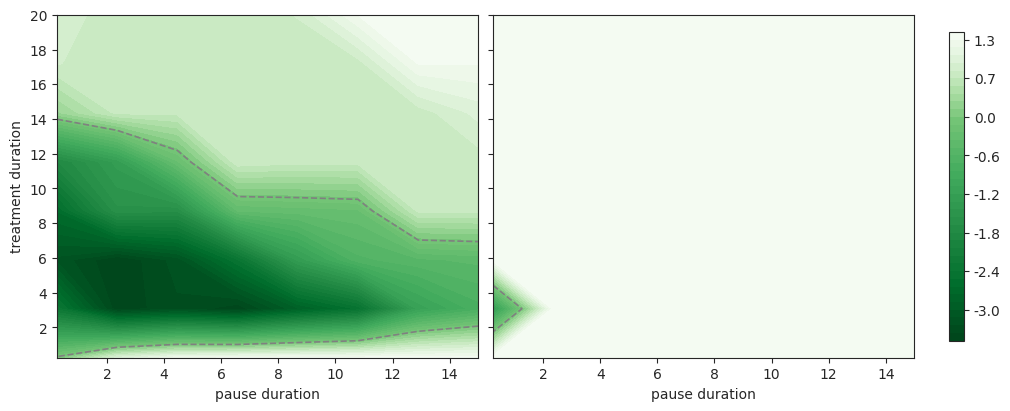

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_V2_D.pdf


In [20]:
# ======================================================================
# Panels I & J: dimensionless VEGF heatmaps for gamma1 = 0.5 and 1.3
# ======================================================================
from scipy.integrate import solve_ivp as _siv_dl
from scipy.optimize import minimize as _minimize_dl
from matplotlib.colors import TwoSlopeNorm, Normalize
from matplotlib.ticker import MaxNLocator


# ── Dimensionless parameters (derived from dimensional ones in cell 12) ──
_kappa1 = k1  * a1_v * mu_v * C0_v / r_E**2   # = 40.0
_kappa2 = k2  * a2_v * mu_v * C0_v / r_E**2   # = 8.0
_gamma2 = c2_v * mu_v * C0_v / r_E

_x1_0  = A1_0 * a1_v / r_E
_x2_0  = A2_0 * a2_v / r_E
_e_0   = E0_v / (mu_v * C0_v)
_y0_dl = [_x1_0, _x2_0, _e_0, 1.0]

print(f"κ₁={_kappa1:.1f}, κ₂={_kappa2:.1f}, γ₂={_gamma2:.2f}")
print(f"IC: x1={_x1_0:.4f}, x2={_x2_0:.4f}, e={_e_0:.4f}, c=1.0")

_T_horizon_dl  = 30.0
_tau_on_grid   = np.linspace(0.25, 20, 8)
_tau_off_grid  = np.linspace(0.25, 15, 8)

def _vegf_dl_rhs(tau, y, treated, gamma1_val):
    x1, x2, e, c = y
    deficit = c - e
    signal  = (treatment_efficacy * x1 if treated else x1) + x2
    return [
        _kappa1 * deficit,
        _kappa2 * deficit,
        e * (signal * (1 - e / 4) - 1),
        c * (gamma1_val - _gamma2 * max(deficit, 0)),
    ]

def _integ_dl(y0, T, treated, gamma1_val):
    sol = _siv_dl(lambda tau, y: _vegf_dl_rhs(tau, y, treated, gamma1_val),
                  (0, T), y0, method='RK45', rtol=1e-4, atol=1e-7)
    res = list(sol.y[:, -1])
    return res if all(np.isfinite(v) for v in res) else None

def _J_dl(tau_on, tau_off, gamma1_val):
    y_cur  = list(_y0_dl)
    c_init = y_cur[3]
    t_el   = 0.0
    while t_el < _T_horizon_dl:
        t_on  = min(tau_on, _T_horizon_dl - t_el)
        y_cur = _integ_dl(y_cur, t_on, True, gamma1_val)
        if y_cur is None: return np.nan
        t_el += t_on
        if t_el >= _T_horizon_dl: break
        t_off = min(tau_off, _T_horizon_dl - t_el)
        y_cur = _integ_dl(y_cur, t_off, False, gamma1_val)
        if y_cur is None: return np.nan
        t_el += t_off
    val = np.log(y_cur[3] / c_init)
    return val if np.isfinite(val) else np.nan

def _compute_heatmap_data(gamma1_val):
    """Calculates the grid values and finds the optimum without plotting."""
    J_grid = np.array([[_J_dl(ton, toff, gamma1_val)
                        for toff in _tau_off_grid]
                       for ton  in _tau_on_grid])
    n_nan = np.sum(~np.isfinite(J_grid))
    print(f"  γ₁={gamma1_val}: {n_nan} NaNs / {J_grid.size}")

    # Optimal via grid + refinement
    best = np.unravel_index(np.nanargmin(J_grid), J_grid.shape)
    res  = _minimize_dl(
        lambda x: _J_dl(x[0], x[1], gamma1_val),
        x0=[_tau_on_grid[best[0]], _tau_off_grid[best[1]]],
        bounds=[(0.1, 15), (0.1, 15)], method='L-BFGS-B'
    )
    return J_grid, res.x[0], res.x[1]

def _plot_heatmap_dl(ax, J_grid, tau_on_opt, tau_off_opt, norm, levels):
    """Plots the heatmap using a pre-computed global norm and levels."""
    J_m = np.ma.masked_invalid(J_grid)
    
    # cmap green - white/grey
    im = ax.contourf(_tau_off_grid, _tau_on_grid, J_m, levels=levels, cmap='Greens_r', norm=norm)
    
    # Only draw the zero-contour line if 0 is within our global range
    if norm.vmin < 0 < norm.vmax:
        ax.contour(_tau_off_grid, _tau_on_grid, J_m,
                   levels=[0], colors='grey', linewidths=1.2, linestyles='--')
                   
    # ax.plot(tau_off_opt, tau_on_opt, 'r*', ms=12,
    #         label=f'Optimum\n$\\tau_{{on}}={tau_on_opt:.2f}$, $\\tau_{{off}}={tau_off_opt:.2f}$')
    ax.set_xlabel('pause duration')
    
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    # clean_ax(ax) # Assuming this is defined elsewhere in your script

    return im

# ── Figure Generation ────────────────────────────────────────────────
fig_IJ, (ax_I, ax_J) = plt.subplots(1, 2, figsize=(10, 4), sharey=True, constrained_layout=True)
print("Computing heatmaps...")

# 1. Compute all data first
J_I, ton_I, toff_I = _compute_heatmap_data(0.2)
J_J, ton_J, toff_J = _compute_heatmap_data(0.8)

# 2. Find global min and max across BOTH datasets
vmin = float(min(np.nanmin(J_I), np.nanmin(J_J)))
vmax = float(max(np.nanmax(J_I), np.nanmax(J_J)))

# 3. Establish the shared color norm based on global bounds
if vmin < 0 < vmax:
    norm   = TwoSlopeNorm(vcenter=0.0, vmin=vmin, vmax=vmax)
    levels = np.linspace(vmin, vmax, 41)
elif vmin >= 0:
    norm   = Normalize(vmin=-vmax, vmax=vmax)
    levels = np.linspace(0.0, vmax, 41)
else:
    norm   = Normalize(vmin=vmin, vmax=-vmin)
    levels = np.linspace(vmin, 0.0, 41)

# 4. Plot both using the shared norm and levels
im_I = _plot_heatmap_dl(ax_I, J_I, ton_I, toff_I, norm, levels)
im_J = _plot_heatmap_dl(ax_J, J_J, ton_J, toff_J, norm, levels)
ax_I.set_ylabel('treatment duration')

# 5. Create a single, accurate colorbar
fig_IJ.colorbar(im_J, ax=[ax_I, ax_J], shrink=0.9, pad=0.04, format="%.1f")

plt.show()

save_fig(fig_IJ, 'figure4_D.pdf')

κ₁=40.0, κ₂=3.2, γ₂=8.00
IC: x1=1.2963, x2=0.0370, e=1.0000, c=1.0
Computing heatmaps...
  γ₁=0.2: 0 NaNs / 64
  γ₁=0.8: 0 NaNs / 64


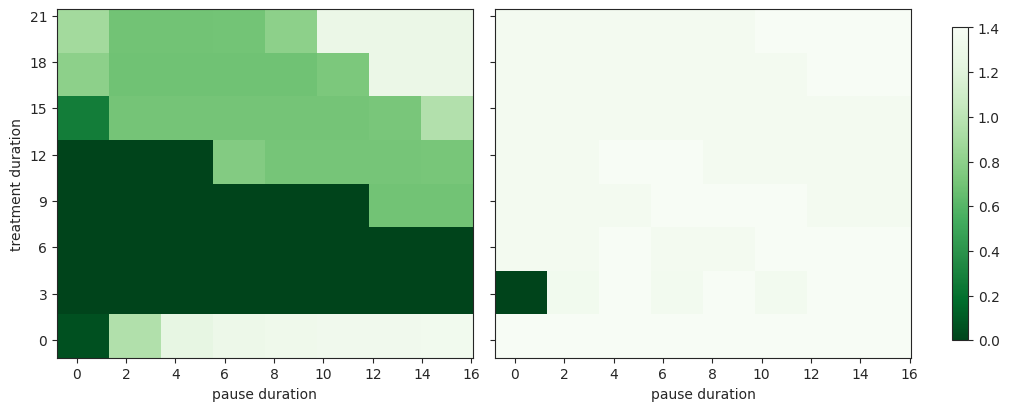

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_V2_D.pdf


In [25]:
# ======================================================================
# Panels I & J: dimensionless VEGF heatmaps for gamma1 = 0.5 and 1.3
# ======================================================================
from scipy.integrate import solve_ivp as _siv_dl
from scipy.optimize import minimize as _minimize_dl
from matplotlib.colors import TwoSlopeNorm, Normalize
from matplotlib.ticker import MaxNLocator


# ── Dimensionless parameters (derived from dimensional ones in cell 12) ──
_kappa1 = k1  * a1_v * mu_v * C0_v / r_E**2   # = 40.0
_kappa2 = k2  * a2_v * mu_v * C0_v / r_E**2   # = 8.0
_gamma2 = c2_v * mu_v * C0_v / r_E

_x1_0  = A1_0 * a1_v / r_E
_x2_0  = A2_0 * a2_v / r_E
_e_0   = E0_v / (mu_v * C0_v)
_y0_dl = [_x1_0, _x2_0, _e_0, 1.0]

print(f"κ₁={_kappa1:.1f}, κ₂={_kappa2:.1f}, γ₂={_gamma2:.2f}")
print(f"IC: x1={_x1_0:.4f}, x2={_x2_0:.4f}, e={_e_0:.4f}, c=1.0")

_T_horizon_dl  = 30.0
_tau_on_grid   = np.linspace(0.25, 20, 8)
_tau_off_grid  = np.linspace(0.25, 15, 8)

def _vegf_dl_rhs(tau, y, treated, gamma1_val):
    x1, x2, e, c = y
    deficit = c - e
    signal  = (treatment_efficacy * x1 if treated else x1) + x2
    return [
        _kappa1 * deficit,
        _kappa2 * deficit,
        e * (signal * (1 - e / 4) - 1),
        c * (gamma1_val - _gamma2 * max(deficit, 0)),
    ]

def _integ_dl(y0, T, treated, gamma1_val):
    sol = _siv_dl(lambda tau, y: _vegf_dl_rhs(tau, y, treated, gamma1_val),
                  (0, T), y0, method='RK45', rtol=1e-4, atol=1e-7)
    res = list(sol.y[:, -1])
    return res if all(np.isfinite(v) for v in res) else None

def _J_dl(tau_on, tau_off, gamma1_val):
    y_cur  = list(_y0_dl)
    c_init = y_cur[3]
    t_el   = 0.0
    while t_el < _T_horizon_dl:
        t_on  = min(tau_on, _T_horizon_dl - t_el)
        y_cur = _integ_dl(y_cur, t_on, True, gamma1_val)
        if y_cur is None: return np.nan
        t_el += t_on
        if t_el >= _T_horizon_dl: break
        t_off = min(tau_off, _T_horizon_dl - t_el)
        y_cur = _integ_dl(y_cur, t_off, False, gamma1_val)
        if y_cur is None: return np.nan
        t_el += t_off
    val = np.log(y_cur[3] / c_init)
    return val if np.isfinite(val) else np.nan

def _compute_heatmap_data(gamma1_val):
    """Calculates the grid values and finds the optimum without plotting."""
    J_grid = np.array([[_J_dl(ton, toff, gamma1_val)
                        for toff in _tau_off_grid]
                       for ton  in _tau_on_grid])
    n_nan = np.sum(~np.isfinite(J_grid))
    print(f"  γ₁={gamma1_val}: {n_nan} NaNs / {J_grid.size}")

    # Optimal via grid + refinement
    best = np.unravel_index(np.nanargmin(J_grid), J_grid.shape)
    res  = _minimize_dl(
        lambda x: _J_dl(x[0], x[1], gamma1_val),
        x0=[_tau_on_grid[best[0]], _tau_off_grid[best[1]]],
        bounds=[(0.1, 15), (0.1, 15)], method='L-BFGS-B'
    )
    return J_grid, res.x[0], res.x[1]

def _plot_heatmap_dl(ax, J_grid, tau_on_opt, tau_off_opt, norm, levels):
    """Plots the heatmap using a pre-computed global norm and levels."""
    J_m = np.ma.masked_invalid(J_grid)
    
    # Use pcolormesh instead of contourf for distinct grid boxes
    im = ax.pcolormesh(_tau_off_grid, _tau_on_grid, J_m, 
                       cmap='Greens_r', norm=norm, shading='nearest')
    
    # Only draw the zero-contour line if 0 is within our global range
    if norm.vmin < 0 < norm.vmax:
        ax.contour(_tau_off_grid, _tau_on_grid, J_m,
                   levels=[0], colors='grey', linewidths=1.2, linestyles='--')
                   
    # ax.plot(tau_off_opt, tau_on_opt, 'r*', ms=12,
    #         label=f'Optimum\n$\\tau_{{on}}={tau_on_opt:.2f}$, $\\tau_{{off}}={tau_off_opt:.2f}$')
    
    ax.set_xlabel('pause duration')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    return im

# ── Figure Generation ────────────────────────────────────────────────
fig_IJ, (ax_I, ax_J) = plt.subplots(1, 2, figsize=(10, 4), sharey=True, constrained_layout=True)
print("Computing heatmaps...")

# 1. Compute all data first
J_I, ton_I, toff_I = _compute_heatmap_data(0.2)
J_J, ton_J, toff_J = _compute_heatmap_data(0.8)

# 2. Find global min and max across BOTH datasets
# vmin = float(min(np.nanmin(J_I), np.nanmin(J_J)))
vmin = 0
vmax = float(max(np.nanmax(J_I), np.nanmax(J_J)))
# norm = Normalize(vmin=vmin, vmax=vmax)
levels = np.linspace(vmin, vmax, 41)

# # 3. Establish the shared color norm based on global bounds
# if vmin < 0 < vmax:
#     norm   = TwoSlopeNorm(vcenter=0.0, vmin=vmin, vmax=vmax)
#     levels = np.linspace(vmin, vmax, 41)
# elif vmin >= 0:
#     norm   = Normalize(vmin=-vmax, vmax=vmax)
#     levels = np.linspace(0.0, vmax, 41)
# else:
#     norm   = Normalize(vmin=vmin, vmax=-vmin)
#     levels = np.linspace(vmin, 0.0, 41)

# 4. Plot both using the shared norm and levels
im_I = _plot_heatmap_dl(ax_I, J_I, ton_I, toff_I, norm, levels)
im_J = _plot_heatmap_dl(ax_J, J_J, ton_J, toff_J, norm, levels)
ax_I.set_ylabel('treatment duration')

# 5. Create a single, accurate colorbar
fig_IJ.colorbar(im_J, ax=[ax_I, ax_J], shrink=0.9, pad=0.04, format="%.1f")

plt.show()

save_fig(fig_IJ, 'figure4_D.pdf')

J_grid min: -3.5208, max: 1.3438


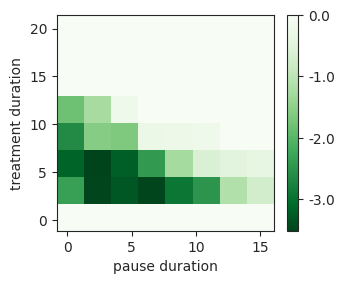

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_V2_0-2.pdf


In [40]:
V_MIN = -3.52

def _J_dl(tau_on, tau_off, gamma1_val):
    y_cur  = list(_y0_dl)
    c_init = y_cur[3]
    t_el   = 0.0
    while t_el < _T_horizon_dl:
        t_on  = min(tau_on, _T_horizon_dl - t_el)
        y_cur = _integ_dl(y_cur, t_on, True, gamma1_val)
        if y_cur is None: return np.nan
        t_el += t_on
        if t_el >= _T_horizon_dl: break
        t_off = min(tau_off, _T_horizon_dl - t_el)
        y_cur = _integ_dl(y_cur, t_off, False, gamma1_val)
        if y_cur is None: return np.nan
        t_el += t_off
    val = np.log(y_cur[3] / c_init)
    return val if np.isfinite(val) else np.nan

tau_on_grid = np.linspace(0.25, 20, 8)
tau_off_grid = np.linspace(0.25, 15, 8)

J_grid = np.array([[_J_dl(ton, toff, 0.2)
                    for toff in tau_off_grid]
                   for ton  in tau_on_grid])

# print min and max of J_grid
print(f"J_grid min: {np.nanmin(J_grid):.4f}, max: {np.nanmax(J_grid):.4f}")

# plot the heatmap without contour lines, using the same colormap and norm as before
# all values >= 0 should be simply white, other values shades of green
fig, ax = plt.subplots(figsize=(5*0.7, 4*0.7))
J_m = np.ma.masked_invalid(J_grid)

# Set vmax=0 so that 0 and everything above it clips to the top of Greens_r (white)
norm = Normalize(vmin=V_MIN, vmax=0)

im = ax.pcolormesh(tau_off_grid, tau_on_grid, J_m,
                   cmap='Greens_r', norm=norm, shading='nearest')

ax.set_xlabel('pause duration')
ax.set_ylabel('treatment duration')
fig.colorbar(im, ax=ax, format="%.1f")
plt.show()

save_fig(fig, 'figure4_0-2.pdf')

J_grid min: -1.2338, max: 1.4031


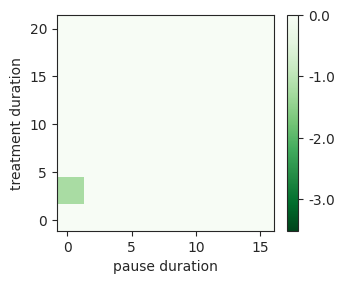

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_V2_0-8.pdf


In [41]:
J_grid = np.array([[_J_dl(ton, toff, 0.8)
                    for toff in tau_off_grid]
                   for ton  in tau_on_grid])

# print min and max of J_grid
print(f"J_grid min: {np.nanmin(J_grid):.4f}, max: {np.nanmax(J_grid):.4f}")

# plot the heatmap without contour lines, using the same colormap and norm as before
# all values >= 0 should be simply white, other values shades of green
fig, ax = plt.subplots(figsize=(5*0.7, 4*0.7))
J_m = np.ma.masked_invalid(J_grid)

# Set vmax=0 so that 0 and everything above it clips to the top of Greens_r (white)
norm = Normalize(vmin=V_MIN, vmax=0)

im = ax.pcolormesh(tau_off_grid, tau_on_grid, J_m,
                   cmap='Greens_r', norm=norm, shading='nearest')

ax.set_xlabel('pause duration')
ax.set_ylabel('treatment duration')
fig.colorbar(im, ax=ax, format="%.1f")
plt.show()

save_fig(fig, 'figure4_0-8.pdf')